# 06 · Multiple reactions and selectivity

Real feeds do more than one thing: the product reacts further, a side reaction consumes reactant, two
paths compete. Then the question is not conversion but *selectivity* - how much of the right product per
unit of the wrong one - and the reactor type, the temperature and the concentration all become levers. This
notebook works through series and parallel reactions, the optimum time for an intermediate, the choice of
reactor, and a general reaction network.

**What you will learn**
- analyse series and parallel reactions and their optimum operating points
- compute selectivity and yield and distinguish them
- choose reactor type, concentration and temperature for selectivity
- integrate reaction networks in batch, PFR, CSTR and semibatch

**Before you start:** notebooks 01 and 03  ·  **Time:** about 75 min

In [1]:
try:                      # on Google Colab (or anywhere engreact is missing): install it from GitHub
    import engreact
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engreact"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engreact import multiple
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Series reactions: A -> B -> C

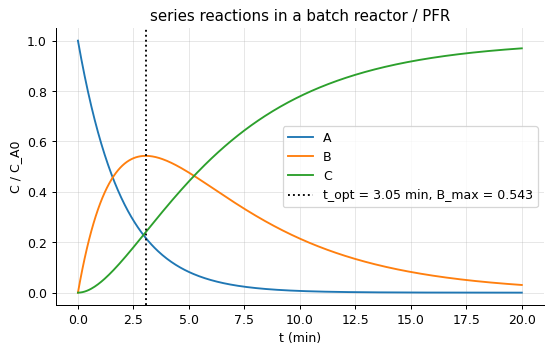

batch/PFR: B_max = 0.543 at t = 3.05 min | CSTR: B_max = 0.375 at tau = 3.16 min


In [2]:
k1, k2 = 0.5, 0.2                                             # 1/min
t = np.linspace(0, 20, 400)
b = multiple.series_batch(k1, k2, 1.0, t)
t_opt, B_max = multiple.series_optimum_time(k1, k2), multiple.series_max_B(k1, k2, 1.0)
fig, ax = plt.subplots()
for s in "ABC":
    ax.plot(t, b[s], label=s)
ax.axvline(t_opt, color="k", ls=":", label=f"t_opt = {t_opt:.2f} min, B_max = {B_max:.3f}")
ax.set(xlabel="t (min)", ylabel="C / C_A0", title="series reactions in a batch reactor / PFR"); ax.legend(); plt.show()
c = multiple.series_cstr(k1, k2, 1.0, t[1:])
tau_opt = multiple.series_cstr_optimum_tau(k1, k2)
print(f"batch/PFR: B_max = {B_max:.3f} at t = {t_opt:.2f} min | CSTR: B_max = {float(multiple.series_cstr(k1, k2, 1.0, tau_opt)['B']):.3f} at tau = {tau_opt:.2f} min")

The intermediate B rises, peaks and decays; the peak is at $t = \ln(k_2/k_1)/(k_2 - k_1)$ and its height
depends only on the ratio $k_1/k_2$. A PFR (or batch) always beats a CSTR for the intermediate: the CSTR
holds B at its outlet concentration, where it is exposed to the second reaction for the whole residence
time. Overshoot the optimum time and you convert your product into waste.

## Parallel reactions: the selectivity lever

In [3]:
kD, kU = 1.0, 0.5                                             # A -> D (desired, order 2), A -> U (undesired, order 1)
for C_A in (0.1, 1.0, 10.0):
    print(f"C_A = {C_A:5.1f}: instantaneous selectivity S_DU = {float(multiple.parallel_selectivity_power_law(kD, kU, 2, 1, C_A)):5.1f}")
net = multiple.Network([({"A": -1, "D": 1}, lambda C: kD * C["A"] ** 2), ({"A": -1, "U": 1}, lambda C: kU * C["A"])])
for name, out in (("PFR", net.pfr({"A": 2.0}, 5.0)), ("CSTR", net.cstr({"A": 2.0}, 5.0))):
    D, U, A = (out["D"][-1], out["U"][-1], out["A"][-1]) if name == "PFR" else (out["D"], out["U"], out["A"])
    print(f"{name}: X = {1 - A/2:.3f}, overall selectivity D/U = {D/U:.2f}, yield of D = {D/(2 - A):.3f}")

C_A =   0.1: instantaneous selectivity S_DU =   0.2
C_A =   1.0: instantaneous selectivity S_DU =   2.0
C_A =  10.0: instantaneous selectivity S_DU =  20.0
PFR: X = 0.982, overall selectivity D/U = 1.55, yield of D = 0.608
CSTR: X = 0.814, overall selectivity D/U = 0.75, yield of D = 0.427


When the desired reaction has the higher order, high concentration favours it: keep the reactant
concentrated - a PFR, no inerts, high pressure for a gas - and the PFR's selectivity beats the CSTR's. If
the undesired reaction had the higher order, everything reverses: a CSTR, dilution, and slow addition. The
orders, not the reactor, decide.

## Temperature as a selectivity lever

In [4]:
from engreact import kinetics
ED, EU = 60e3, 90e3                                            # activation energies, J/mol
for T in (300, 350, 400, 450):
    ratio = kinetics.arrhenius(1.0, ED, T) / kinetics.arrhenius(1.0, EU, T)
    print(f"T = {T} K: kD/kU relative to 300 K = {ratio / (kinetics.arrhenius(1.0, ED, 300.0) / kinetics.arrhenius(1.0, EU, 300.0)):.3f}")

T = 300 K: kD/kU relative to 300 K = 1.000
T = 350 K: kD/kU relative to 300 K = 0.179
T = 400 K: kD/kU relative to 300 K = 0.049
T = 450 K: kD/kU relative to 300 K = 0.018


The reaction with the larger activation energy speeds up more with temperature. If the *undesired* path has
the larger $E_a$, run cold; if the desired one does, run hot. Selectivity is often the reason a reactor runs
at a temperature that looks slow.

## A reaction network in a semibatch reactor

In [5]:
# A + B -> D (desired, k = 1), B + D -> U (undesired, k = 0.5): add B slowly to keep it low
netw = multiple.Network([({"A": -1, "B": -1, "D": 1}, lambda C: 1.0 * C["A"] * C["B"]), ({"B": -1, "D": -1, "U": 1}, lambda C: 0.5 * C["B"] * C["D"])])
t = np.linspace(0, 20, 200)
allatonce = netw.batch({"A": 1.0, "B": 1.0}, t)
semi = netw.semibatch({"A": 2.0}, V0=0.5, feed_C={"B": 2.0}, v_in=0.5 / 10.0, t=np.linspace(0, 10, 200))   # B fed over 10 min into the same total volume
print(f"all at once (batch, 20 min): D = {allatonce['D'][-1]:.3f}, U = {allatonce['U'][-1]:.3f}, D/U = {allatonce['D'][-1]/allatonce['U'][-1]:.2f}")
print(f"semibatch (B fed over 10 min): D = {semi['D'][-1]:.3f}, U = {semi['U'][-1]:.3f}, D/U = {semi['D'][-1]/semi['U'][-1]:.2f} (final volume {semi['V'][-1]:.2f})")

all at once (batch, 20 min): D = 0.500, U = 0.250, D/U = 2.00
semibatch (B fed over 10 min): D = 0.489, U = 0.182, D/U = 2.69 (final volume 1.00)


Adding B slowly keeps its concentration low, which starves the undesired reaction (first order in B and in
D) more than the desired one: selectivity doubles. Semibatch operation is the standard trick for exothermic
or selectivity-sensitive chemistry - and the `Network` class handles any scheme, in any of the ideal
reactors, from a list of reactions and rate laws.

## Yield, selectivity, conversion: three different numbers

In [6]:
out = net.pfr({"A": 2.0}, 5.0)
A, D, U = out["A"][-1], out["D"][-1], out["U"][-1]
print(f"conversion of A: {1 - A/2:.3f} | overall selectivity S_DU = D/U = {D/U:.2f} | overall yield Y_D = D/(A0 - A) = {D/(2-A):.3f} | D per mole fed = {D/2:.3f}")

conversion of A: 0.982 | overall selectivity S_DU = D/U = 1.55 | overall yield Y_D = D/(A0 - A) = 0.608 | D per mole fed = 0.597


Conversion says how much reactant is gone, selectivity how it split, yield how much of it became product.
A plant is judged on yield and on the cost of separating U; a high conversion with poor selectivity is
usually worse than a low conversion with recycle. Keep the three numbers apart - and check which definition
a paper uses, because two conventions for selectivity are in circulation.

## Inside the algorithm: Bateman's solution

In [7]:
tt = 3.0
B_hand = 1.0 * k1 / (k2 - k1) * (np.exp(-k1 * tt) - np.exp(-k2 * tt))
print("by hand:", B_hand, " library:", float(multiple.series_batch(k1, k2, 1.0, tt)["B"]))

by hand: 0.5428024599093277  library: 0.5428024599093277


## Exercises
1. For A -> B -> C with k1 = 0.5 and k2 = 0.2 1/min, find the CSTR residence time and the PFR space time that each give 90 % conversion of A, and compare the yields of B. Which reactor would you choose if B is the product, and if C is?
2. Two parallel reactions A -> D (first order, Ea = 40 kJ/mol) and A -> U (second order, Ea = 80 kJ/mol). Using `Network`, find the combination of temperature (300-400 K) and feed concentration (0.1-10 mol/L) that maximises the selectivity D/U in a PFR at 90 % conversion.
3. **Implement it yourself:** solve A -> B -> C in a batch reactor with solve_ivp and locate the time of maximum B numerically; compare with `multiple.series_optimum_time`.